# 🧮 nanoCalc-GPT: Training on Google Colab GPU

This notebook trains **nanoCalc-GPT**, a character-level decoder-only Transformer designed to perform 2-digit arithmetic (`+`, `-`, `*`, `/`).

### ⚡ Quick Colab Setup
1. **Enable GPU:** Go to **Runtime** > **Change runtime type** > Select **T4 GPU** (or any available GPU).
2. **Access Original Data:** Run **Section 0** below. It will automatically clone your GitHub repository into Colab so `data/train.txt` and `data/test.txt` are immediately available.
3. **Run Training:** Click **Runtime** > **Run all**.


## 0. Colab Setup: Access Original `data/train.txt`
Google Colab runs on an isolated cloud VM (`/content`). When you open this notebook in Colab, your local files aren't automatically present.
The code below automatically clones your repository (`https://github.com/LochanJangid/nanocalc-gpt.git`) into Colab and switches into the project folder so that `data/train.txt` is ready immediately.


In [1]:
# =====================================================================
# 🚀 AUTOMATIC COLAB SETUP: Clone repo to access original data/train.txt
# =====================================================================
import os
import sys

# Detect if running in Google Colab
IN_COLAB = "google.colab" in sys.modules or "COLAB_GPU" in os.environ

if IN_COLAB:
    REPO_URL = "https://github.com/LochanJangid/nanocalc-gpt.git"
    REPO_DIR = "nanocalc-gpt"

    # If data/train.txt is not yet in the current working directory
    if not os.path.exists("data/train.txt"):
        if not os.path.exists(REPO_DIR):
            print(f"📥 Cloning repository from {REPO_URL}...")
            os.system(f"git clone {REPO_URL}")
        if os.path.exists(REPO_DIR):
            os.chdir(REPO_DIR)
            print(f"📁 Switched working directory to: {os.getcwd()}")

    if os.path.exists("data/train.txt"):
        n_lines = sum(1 for _ in open("data/train.txt"))
        print(f"✅ Found original data/train.txt ({n_lines:,} examples)!")
    else:
        print("⚠️ data/train.txt not found via git clone; it will be verified/generated in Section 2.")
else:
    print(f"Running locally in: {os.getcwd()}")
    if os.path.exists("data/train.txt"):
        print(f"✅ Found original data/train.txt ({sum(1 for _ in open('data/train.txt')):,} examples)")


✅ Found original data/train.txt (36,000 examples)!


## 1. Environment & GPU Setup
Check CUDA availability and verify the active GPU.


In [2]:
import os
import random
import time
from collections import defaultdict
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Tuple, Union

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
if device == "cuda":
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"Allocated VRAM: {torch.cuda.memory_allocated(0) / 1e6:.1f} MB")
    print(f"Total VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("⚠️ WARNING: GPU not active! In Colab, go to Runtime -> Change runtime type -> Hardware accelerator -> T4 GPU.")

SEED = 1337
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
random.seed(SEED)


Using device: cuda
GPU Name: Tesla T4
Allocated VRAM: 0.0 MB
Total VRAM: 15.64 GB


## 2. Dataset Verification & Fallback Generation
Checks that `data/train.txt` and `data/test.txt` exist. If they do not, it automatically generates the exact 36,000 balanced arithmetic examples (`+`, `-`, `*`, `/`).


In [3]:
WIDTH = 2
N = 10 ** WIDTH  # 100 operands (00 to 99)
TEST_FRAC = 0.1
DATA_DIR = Path("data")

# Division keeps normal written order (MSB first, like long division, e.g. 66/06=+0011).
# Only +, -, * have their answer digits reversed (LSB first for carry propagation).
REVERSED_OPS = {"+", "-", "*"}

def arith_result(a: int, op: str, b: int):
    return {"+": a + b, "-": a - b, "*": a * b, "/": a // b if b else None}[op]

def fmt_example(a: int, op: str, b: int) -> str:
    r = arith_result(a, op, b)
    sign = "-" if r < 0 else "+"
    digits = str(abs(r)).zfill(4)
    if op in REVERSED_OPS:
        digits = digits[::-1]
    return f"{a:02d}{op}{b:02d}={sign}{digits}\n"

def decode_example(line: str) -> int:
    op = line[2]
    ans = line.strip().split("=")[1]
    digits = ans[1:]
    if op in REVERSED_OPS:
        digits = digits[::-1]
    v = int(digits)
    return -v if ans[0] == "-" else v

def all_arith_examples() -> Dict[str, List[Tuple[int, str, int]]]:
    ex = defaultdict(list)
    for a in range(N):
        for b in range(N):
            ex["+"].append((a, "+", b))
            ex["-"].append((a, "-", b))
            ex["*"].append((a, "*", b))
            if b != 0 and a % b == 0:
                ex["/"].append((a, "/", b))
    return ex

def ensure_dataset(data_dir: Path = DATA_DIR, force: bool = False):
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    train_path = data_dir / "train.txt"
    test_path = data_dir / "test.txt"

    # Verify if existing file has the new format (66/06=+0011 instead of +1100)
    if train_path.exists() and test_path.exists() and not force:
        with open(train_path) as f:
            txt = f.read()
        if "66/06=+1100" in txt:
            print("⚠️ Found old reversed division (+1100) in data/train.txt. Re-generating with new format (+0011)...")
        else:
            n_train = len(txt.splitlines())
            n_test = sum(1 for _ in open(test_path))
            print(f"✅ Verified dataset: {train_path} ({n_train:,} lines), {test_path} ({n_test:,} lines)")
            return

    print("Generating balanced arithmetic dataset (new division format: 66/06=+0011)...\n")
    random.seed(SEED)
    train, test = [], []
    by_op_train = {}
    for op, items in all_arith_examples().items():
        random.shuffle(items)
        n_test = int(len(items) * TEST_FRAC)
        test += items[:n_test]
        by_op_train[op] = items[n_test:]
        print(f"Operator '{op}': {len(items)} unique -> train {len(items) - n_test}, test {n_test}")

    target = max(len(v) for v in by_op_train.values())
    for op, items in by_op_train.items():
        reps = items * (target // len(items)) + items[: target % len(items)]
        train += reps

    random.shuffle(train)
    random.shuffle(test)

    for name, ps in (("train", train), ("test", test)):
        lines = [fmt_example(*e) for e in ps]
        assert all(len(l) == 12 for l in lines), "Every example must be exactly 12 characters!"
        out_path = data_dir / f"{name}.txt"
        with open(out_path, "w", encoding="utf-8") as f:
            f.write("".join(lines))
        print(f"Wrote {out_path}: {len(lines)} examples")

ensure_dataset()


⚠️ Found old reversed division (+1100) in data/train.txt. Re-generating with new format (+0011)...
Generating balanced arithmetic dataset (new division format: 66/06=+0011)...

Operator '+': 10000 unique -> train 9000, test 1000
Operator '-': 10000 unique -> train 9000, test 1000
Operator '*': 10000 unique -> train 9000, test 1000
Operator '/': 572 unique -> train 515, test 57
Wrote data/train.txt: 36000 examples
Wrote data/test.txt: 3057 examples


## 3. Tokenizer & Batching
Character-level vocabulary: `0123456789+*-/=\n` (16 unique characters).


In [4]:
chars = list("0123456789+*-/=\n")
stoi = {s: i for i, s in enumerate(chars)}
itos = {i: s for s, i in stoi.items()}
vocab_size = len(itos)
print(f"Vocabulary size: {vocab_size} | Tokens: {''.join(chars).strip()}")

encode = lambda x: torch.tensor([stoi[s] for s in x], dtype=torch.long)
decode = lambda x: "".join([itos[i.item()] for i in x])

train_text = [ch for line in open("data/train.txt").readlines() for ch in line.strip() + "\n"]
test_text = [ch for line in open("data/test.txt").readlines() for ch in line.strip() + "\n"]

train_data = encode(train_text)
test_data = encode(test_text)
print(f"Loaded train tokens: {len(train_data):,}, test tokens: {len(test_data):,}")

def get_batch(split="train", device="cuda", batch_size=128, context_size=12):
    data = train_data if split == "train" else test_data
    num_examples = len(data) // 12
    rand_idx = torch.randint(0, num_examples - 1, (batch_size,)) * 12
    X = torch.stack([data[i : i + context_size] for i in rand_idx])
    y = torch.stack([data[i + 1 : i + 1 + context_size] for i in rand_idx])
    return X.to(device), y.to(device)

x_sample, y_sample = get_batch("train", device="cpu", batch_size=1)
print(f"Sample Input : {decode(x_sample[0])!r}")
print(f"Sample Target: {decode(y_sample[0])!r}")


Vocabulary size: 16 | Tokens: 0123456789+*-/=
Loaded train tokens: 432,000, test tokens: 36,684
Sample Input : '66/06=+0011\n'
Sample Target: '6/06=+0011\n5'


## 4. nanoCalc-GPT Transformer Architecture
- Pre-LN Multi-Head Causal Self-Attention
- FeedForward MLP with expansion factor 4
- Token and learned Positional Embeddings


In [6]:
@dataclass
class GPTConfig:
    context_size: int = 12
    vocab_size: int = 16
    n_emb: int = 128        # Embedding dimension
    n_head: int = 4         # Attention heads
    head_size: Optional[int] = None
    n_blocks: int = 6       # Transformer layers
    batch_size: int = 128
    epochs: int = 30000     # 30,000 steps (~2-3 mins on Colab GPU)
    lr: float = 1e-3
    eval_iter: int = 50
    eval_time: Optional[int] = None
    device: str = "cuda" if torch.cuda.is_available() else "cpu"

    def __post_init__(self):
        if self.head_size is None:
            self.head_size = self.n_emb // self.n_head
        if self.eval_time is None:
            self.eval_time = max(1, self.epochs // 20)


class CasualMultiHeadAttention(nn.Module):
    def __init__(self, config: GPTConfig):
        super().__init__()
        self.n_head = config.n_head
        self.head_size = config.head_size
        self.query = nn.Linear(config.n_emb, config.n_emb)
        self.key = nn.Linear(config.n_emb, config.n_emb)
        self.value = nn.Linear(config.n_emb, config.n_emb)
        self.register_buffer("mask", torch.tril(torch.ones(config.context_size, config.context_size)))
        self.proj = nn.Linear(config.n_emb, config.n_emb)

    def forward(self, x):
        B, T, C = x.shape
        Q = self.query(x).view(B, T, self.n_head, self.head_size).transpose(1, 2)
        K = self.key(x).view(B, T, self.n_head, self.head_size).transpose(1, 2)
        V = self.value(x).view(B, T, self.n_head, self.head_size).transpose(1, 2)

        scores = (Q @ K.transpose(-2, -1)) / (self.head_size ** 0.5)
        scores = scores.masked_fill(self.mask[:T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        out = (weights @ V).transpose(1, 2).contiguous().view(B, T, C)
        return self.proj(out)


class FeedForward(nn.Module):
    def __init__(self, config: GPTConfig):
        super().__init__()
        hidden = 4 * config.n_emb
        self.ff = nn.Sequential(
            nn.Linear(config.n_emb, hidden),
            nn.ReLU(),
            nn.Linear(hidden, config.n_emb),
        )

    def forward(self, x):
        return self.ff(x)


class Block(nn.Module):
    def __init__(self, config: GPTConfig):
        super().__init__()
        self.ln1 = nn.LayerNorm(config.n_emb)
        self.mh = CasualMultiHeadAttention(config)
        self.ln2 = nn.LayerNorm(config.n_emb)
        self.ff = FeedForward(config)

    def forward(self, x):
        x = x + self.mh(self.ln1(x))
        x = x + self.ff(self.ln2(x))
        return x


class GPT(nn.Module):
    def __init__(self, config: Optional[GPTConfig] = None):
        super().__init__()
        self.config = config or GPTConfig()
        cfg = self.config

        self.token_embedding = nn.Embedding(cfg.vocab_size, cfg.n_emb)
        self.positional_embedding = nn.Embedding(cfg.context_size, cfg.n_emb)
        self.blocks = nn.Sequential(*[Block(cfg) for _ in range(cfg.n_blocks)])
        self.l_norm = nn.LayerNorm(cfg.n_emb)
        self.ln_layer = nn.Linear(cfg.n_emb, cfg.vocab_size)

    def forward(self, x):
        B, T = x.shape
        pos = torch.arange(0, T, device=x.device)
        tok_pos = self.token_embedding(x) + self.positional_embedding(pos)
        out = self.l_norm(self.blocks(tok_pos))
        return self.ln_layer(out)

    def get_num_params(self, non_embedding: bool = False) -> int:
        n_params = sum(p.numel() for p in self.parameters())
        if non_embedding:
            n_params -= self.positional_embedding.weight.numel()
            n_params -= self.token_embedding.weight.numel()
        return n_params

    @torch.no_grad()
    def generate(self, idx: torch.Tensor, max_new_tokens: int = 5) -> torch.Tensor:
        for _ in range(max_new_tokens):
            idx_cond = idx if idx.size(1) <= self.config.context_size else idx[:, -self.config.context_size:]
            logits = self(idx_cond)
            idx_next = torch.argmax(logits[:, -1, :], dim=-1, keepdim=True)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx


config = GPTConfig()
model = GPT(config).to(config.device)
print(f"Model initialized on: {config.device}")
print(f"Total Parameters         : {model.get_num_params():,}")
print(f"Non-Embedding Parameters : {model.get_num_params(non_embedding=True):,}")


Model initialized on: cuda
Total Parameters         : 1,195,536
Non-Embedding Parameters : 1,191,952


## 5. GPU Training Loop
- Evaluates cross entropy specifically on calculation output tokens (indices `5:11`).
- `AdamW` (weight decay = 0.1) and `OneCycleLR`.


In [7]:
@torch.no_grad()
def estimate_loss(model, config, eval_iters=50):
    model.eval()
    out = {}
    for split in ["train", "test"]:
        losses = []
        for _ in range(eval_iters):
            x, y = get_batch(split, device=config.device, batch_size=config.batch_size, context_size=config.context_size)
            logits = model(x)
            loss = F.cross_entropy(logits[:, 5:11].reshape(-1, config.vocab_size), y[:, 5:11].reshape(-1))
            losses.append(loss.item())
        out[split] = sum(losses) / len(losses)
    model.train()
    return out

epochs = config.epochs
eval_interval = config.eval_time
lr = config.lr

optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.1)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=lr, total_steps=epochs, pct_start=0.03, anneal_strategy="cos"
)

train_loss_history = []
test_loss_history = []
step_history = []

print(f"Starting training on {config.device} for {epochs:,} steps...")
t_start = time.time()
model.train()

for step in range(epochs):
    if step % eval_interval == 0:
        losses = estimate_loss(model, config)
        elapsed = time.time() - t_start
        cur_lr = scheduler.get_last_lr()[0]
        step_history.append(step)
        train_loss_history.append(losses['train'])
        test_loss_history.append(losses['test'])
        print(f"Step {step:5d}/{epochs} | Train Loss: {losses['train']:.4f} | Test Loss: {losses['test']:.4f} | LR: {cur_lr:.2e} | Elapsed: {elapsed:.1f}s")

    x, y = get_batch("train", device=config.device, batch_size=config.batch_size, context_size=config.context_size)
    logits = model(x)
    loss = F.cross_entropy(logits[:, 5:11].reshape(-1, config.vocab_size), y[:, 5:11].reshape(-1))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    scheduler.step()

final_losses = estimate_loss(model, config)
step_history.append(epochs)
train_loss_history.append(final_losses['train'])
test_loss_history.append(final_losses['test'])
print(f"Step {epochs:5d}/{epochs} | Final Train Loss: {final_losses['train']:.4f} | Final Test Loss: {final_losses['test']:.4f}")
print(f"\nTraining complete in {time.time() - t_start:.2f} seconds!")


Starting training on cuda for 30,000 steps...
Step     0/30000 | Train Loss: 3.0668 | Test Loss: 3.1034 | LR: 4.00e-05 | Elapsed: 0.9s
Step  1500/30000 | Train Loss: 0.1681 | Test Loss: 0.2233 | LR: 9.99e-04 | Elapsed: 29.8s
Step  3000/30000 | Train Loss: 0.0991 | Test Loss: 0.1447 | LR: 9.87e-04 | Elapsed: 58.0s
Step  4500/30000 | Train Loss: 0.0659 | Test Loss: 0.0977 | LR: 9.63e-04 | Elapsed: 87.0s
Step  6000/30000 | Train Loss: 0.0514 | Test Loss: 0.0807 | LR: 9.26e-04 | Elapsed: 116.5s
Step  7500/30000 | Train Loss: 0.0345 | Test Loss: 0.0623 | LR: 8.78e-04 | Elapsed: 145.8s
Step  9000/30000 | Train Loss: 0.0261 | Test Loss: 0.0409 | LR: 8.21e-04 | Elapsed: 173.8s
Step 10500/30000 | Train Loss: 0.0114 | Test Loss: 0.0286 | LR: 7.55e-04 | Elapsed: 202.2s
Step 12000/30000 | Train Loss: 0.0084 | Test Loss: 0.0200 | LR: 6.82e-04 | Elapsed: 230.8s
Step 13500/30000 | Train Loss: 0.0098 | Test Loss: 0.0232 | LR: 6.04e-04 | Elapsed: 259.1s
Step 15000/30000 | Train Loss: 0.0073 | Test Loss

## 6. Training & Validation Loss Curves


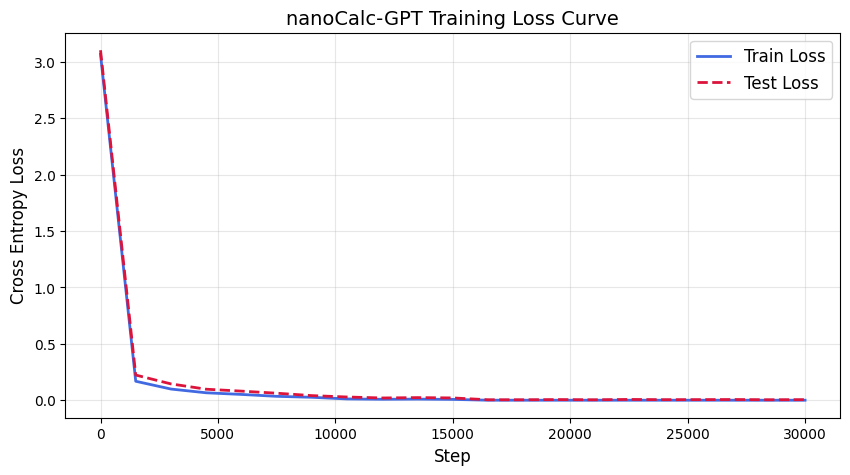

In [8]:
plt.figure(figsize=(10, 5))
plt.plot(step_history, train_loss_history, label="Train Loss", color="royalblue", lw=2)
plt.plot(step_history, test_loss_history, label="Test Loss", color="crimson", lw=2, linestyle="--")
plt.xlabel("Step", fontsize=12)
plt.ylabel("Cross Entropy Loss", fontsize=12)
plt.title("nanoCalc-GPT Training Loss Curve", fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)
plt.savefig("loss_curve.png", dpi=200, bbox_inches="tight")
plt.show()


## 7. Exact Match Evaluation (Full Test Set)
Evaluates autoregressive generation on every test example across all operands (`+`, `-`, `*`, `/`).


In [14]:
@torch.no_grad()
def evaluate_exact_match(model, split="test", batch_size=512):
    model.eval()
    data_path = f"data/{split}.txt"
    lines = [line.strip() for line in open(data_path).readlines() if line.strip()]

    op_names = {"+": "Addition", "-": "Subtraction", "*": "Multiplication", "/": "Division"}
    by_op = {op: {"total": 0, "correct": 0, "errors": 0} for op in op_names}
    error_samples = []

    for i in range(0, len(lines), batch_size):
        chunk = lines[i : i + batch_size]
        prompts = [line[:6] for line in chunk]
        expected_ans = [line[6:11] for line in chunk]
        ops = [p[2] for p in prompts]

        x = torch.stack([encode(p) for p in prompts]).to(config.device)
        for _ in range(5):
            logits = model(x)
            nxt = torch.argmax(logits[:, -1, :], dim=-1, keepdim=True)
            x = torch.cat([x, nxt], dim=1)

        preds = [decode(seq[6:11]) for seq in x]

        for p_str, pred_str, exp_str, op in zip(prompts, preds, expected_ans, ops):
            by_op[op]["total"] += 1
            if pred_str == exp_str:
                by_op[op]["correct"] += 1
            else:
                by_op[op]["errors"] += 1
                if len(error_samples) < 10:
                    error_samples.append((p_str, pred_str, exp_str))

    total = sum(v["total"] for v in by_op.values())
    correct = sum(v["correct"] for v in by_op.values())
    overall_acc = correct / total if total else 0.0

    print(f"=== Exact Match Evaluation | Split: {split} ===")
    print(f"Overall Accuracy: {correct}/{total} ({overall_acc:.2%})\n")
    print("+--------------------+---------+---------+--------+----------+")
    print("| Operator           |   Total | Correct | Errors | Accuracy |")
    print("+--------------------+---------+---------+--------+----------+")
    for op in sorted(by_op.keys()):
        v = by_op[op]
        acc = v["correct"] / v["total"] if v["total"] else 0.0
        label = f"{op} ({op_names[op]})"
        print(f"| {label:<18} | {v['total']:>7} | {v['correct']:>7} | {v['errors']:>6} | {acc:>7.2%} |")
    print("+--------------------+---------+---------+--------+----------+")
    print(f"| {'Overall':<18} | {total:>7} | {correct:>7} | {total - correct:>6} | {overall_acc:>7.2%} |")
    print("+--------------------+---------+---------+--------+----------+")

    if error_samples:
        print("\nSample Error Cases (Prompt -> Predicted vs Expected):")
        for p, pred, exp in error_samples[:5]:
            print(f"  {p} -> Pred: {pred!r} | Expected: {exp!r}")

evaluate_exact_match(model, split="test")


=== Exact Match Evaluation | Split: test ===
Overall Accuracy: 3042/3057 (99.51%)

+--------------------+---------+---------+--------+----------+
| Operator           |   Total | Correct | Errors | Accuracy |
+--------------------+---------+---------+--------+----------+
| * (Multiplication) |    1000 |     993 |      7 |  99.30% |
| + (Addition)       |    1000 |    1000 |      0 | 100.00% |
| - (Subtraction)    |    1000 |    1000 |      0 | 100.00% |
| / (Division)       |      57 |      49 |      8 |  85.96% |
+--------------------+---------+---------+--------+----------+
| Overall            |    3057 |    3042 |     15 |  99.51% |
+--------------------+---------+---------+--------+----------+

Sample Error Cases (Prompt -> Predicted vs Expected):
  84/06= -> Pred: '+0011' | Expected: '+0014'
  88/04= -> Pred: '+0023' | Expected: '+0022'
  82*72= -> Pred: '+4006' | Expected: '+4095'
  08*67= -> Pred: '+6750' | Expected: '+6350'
  52/04= -> Pred: '+0018' | Expected: '+0013'


## 8. Interactive Calculator Playground
Test arbitrary 2-digit arithmetic expressions.


In [15]:
REVERSED_OPS = {"+", "-", "*"}

def decode_nanocalc_ans(raw_ans: str, op: str = "+") -> Optional[int]:
    raw = raw_ans.strip()
    if not raw or raw[0] not in ("+", "-"):
        return None
    try:
        sign = -1 if raw[0] == "-" else 1
        digits = raw[1:]
        if op in REVERSED_OPS:
            digits = digits[::-1]
        return sign * int(digits)
    except Exception:
        return None

@torch.no_grad()
def calculate(expr: str):
    """Accepts expressions like '37*14', '80/08', '42+58', '19-45'"""
    model.eval()
    expr = expr.replace(" ", "").rstrip("=")
    for op in ["+", "-", "*", "/"]:
        if op in expr[1:]:
            parts = expr.split(op)
            a, b = int(parts[0]), int(parts[1])
            prompt = f"{a:02d}{op}{b:02d}="
            expected = arith_result(a, op, b)
            cur_op = op
            break
    else:
        raise ValueError(f"Could not parse arithmetic expression: {expr}")

    x = encode(prompt).unsqueeze(0).to(config.device)
    for _ in range(5):
        logits = model(x)
        nxt = torch.argmax(logits[:, -1, :], dim=-1, keepdim=True)
        x = torch.cat([x, nxt], dim=1)

    raw_output = decode(x[0, 6:11])
    predicted_val = decode_nanocalc_ans(raw_output, op=cur_op)
    is_correct = (predicted_val == expected)

    status = "✅ Correct" if is_correct else "❌ Error"
    print(f"{prompt} -> Raw: '{raw_output}' -> Decoded: {predicted_val} (Expected: {expected}) [{status}]")

print("Testing interactive calculations:")
for test_expr in ["12 + 34", "89 - 42", "23 * 04", "84 / 06", "15 - 99", "99 * 99"]:
    calculate(test_expr)


Testing interactive calculations:
12+34= -> Raw: '+6400' -> Decoded: 46 (Expected: 46) [✅ Correct]
89-42= -> Raw: '+7400' -> Decoded: 47 (Expected: 47) [✅ Correct]
23*04= -> Raw: '+2900' -> Decoded: 92 (Expected: 92) [✅ Correct]
84/06= -> Raw: '+0011' -> Decoded: 11 (Expected: 14) [❌ Error]
15-99= -> Raw: '-4800' -> Decoded: -84 (Expected: -84) [✅ Correct]
99*99= -> Raw: '+1089' -> Decoded: 9801 (Expected: 9801) [✅ Correct]


## 9. Save Checkpoint & Export to Local Machine
Save your trained model checkpoint (with `n_emb=128`, `n_blocks=6` and ~99.51% accuracy).

> **Important Note for VS Code Users**:
> If you are connected to Colab as a **Remote Kernel inside VS Code**, browser downloads (`files.download`) are blocked by VS Code for security.
> Use **Option B (Google Drive)** or **Option C (Direct Transfer Link)** below to get `artifacts/model.pt` onto your local computer.


In [18]:
from dataclasses import asdict
import os
import subprocess
from IPython.display import HTML, display

# 1. Save checkpoint inside the environment (exact same format as train.py)
os.makedirs("artifacts", exist_ok=True)
checkpoint_path = "artifacts/model.pt"

torch.save({
    "model_state_dict": model.state_dict(),
    "config": asdict(config),
}, checkpoint_path)
file_size_mb = os.path.getsize(checkpoint_path) / (1024 * 1024)
print(f"✅ Checkpoint saved: {checkpoint_path} ({file_size_mb:.2f} MB)")

# --- Method 1: Browser Download (for colab.research.google.com in Chrome/Firefox) ---
if IN_COLAB:
    try:
        from google.colab import files
        print("\n⬇️ [Method 1] Triggering browser download via Colab API...")
        files.download(checkpoint_path)
    except Exception as e:
        print(f"Browser download skipped: {e}")

# --- Method 2: Direct 1-Click Link & Terminal Command (Works in VS Code Remote Kernel!) ---
print("\n🌐 [Method 2] Generating direct local download link & terminal command...")
download_url = None
try:
    res = subprocess.run(
        ["curl", "-s", "-F", "reqtype=fileupload", f"fileToUpload=@{checkpoint_path}", "https://catbox.moe/user/api.php"],
        capture_output=True, text=True, timeout=30
    )
    out = res.stdout.strip()
    if out.startswith("http"):
        download_url = out
        print("\n" + "="*70)
        print("🚀 TO SAVE DIRECTLY INTO YOUR LOCAL artifacts/model.pt:")
        print("Run this command in your local VS Code terminal:")
        print(f"   curl -L {download_url} -o artifacts/model.pt")
        print("="*70 + "\n")
        display(HTML(f"""<div style="padding:12px; background:#e8f0fe; border-radius:8px; border:1px solid #1a73e8; margin:10px 0;">
            <a href="{download_url}" target="_blank" style="font-size:16px; font-weight:bold; color:#1a73e8; text-decoration:none;">
                📥 Click Here to Download model.pt to your computer
            </a>
        </div>"""))
except Exception as e:
    print(f"Direct link generation error: {e}")


Checkpoint saved: artifacts/model.pt (4.59 MB)

[Option A] Triggering browser download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


[Option B] Generating local download command for VS Code users...


In [19]:
# [Option C] Save model.pt directly to Google Drive
from google.colab import drive
import shutil

drive.mount("/content/drive")
drive_target = "/content/drive/MyDrive/model.pt"
shutil.copy("artifacts/model.pt", drive_target)
print(f"Saved to your Google Drive: {drive_target}")


Mounted at /content/drive
Saved to your Google Drive: /content/drive/MyDrive/model.pt
